# Bank Marketing — Model Experiments

## 1. Introduction

### 1.1 Objective & Scope

This notebook improves on the Logistic Regression baseline and selects one frozen model configuration for final evaluation. The unit is a campaign record, and prediction occurs immediately before a planned contact.

Experiments follow **Hypothesis → Experiment → Evaluation → Decision**. Average Precision (AP) is primary; ROC-AUC and record-based Precision@K, Recall@K, and Lift@K at 5%, 10%, and 20% are supporting metrics.

The established feature policy is preserved: `duration` is excluded, while the remaining 19 predictors are retained. Train is used for fitting and time-aware cross-validation, Validation for development decisions, and Test remains untouched.

### 1.2 Baseline Recap

The stored baseline uses `LogisticRegression(max_iter=1000)`, scaled numerical features including raw `pdays`, and one-hot encoded categorical features. Its recorded Validation AP is **0.297231** and ROC-AUC is **0.692923**. These are references until reproduced below.

### 1.3 Experiment Plan

1. Reproduce the baseline and evaluation protocol.
2. Compare raw `pdays` with an explicit previous-contact representation.
3. Compare Logistic Regression, Random Forest, and HistGradientBoosting with time-aware cross-validation.
4. Tune Logistic Regression and the strongest nonlinear family on Train only.
5. Evaluate the frozen candidates on Validation and apply a predeclared selection rule.
6. Analyze temporal stability and permutation importance without consulting Test.

## 2. Experimental Setup

Use a fixed seed, deterministic split boundaries, stable score sorting, and the locked environment. The project root is discovered from either the repository root or `notebooks/`.

Only the first 90% of rows are materialized as Train and Validation. No Test dataframe, target, distribution, or metric is created in this notebook.

In [1]:
import platform
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    TimeSeriesSplit,
    cross_validate,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

RANDOM_STATE = 42
TOP_FRACTIONS = (0.05, 0.10, 0.20)
EXPECTED_BASELINE_AP = 0.297231
EXPECTED_BASELINE_ROC_AUC = 0.692923
BASELINE_TOLERANCE = 5e-6

cwd = Path.cwd().resolve()
if (cwd / "pyproject.toml").exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / "pyproject.toml").exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError("Run from the project root or notebooks directory.")

RAW_DATA_PATH = (
    PROJECT_ROOT / "data" / "raw" / "bank-additional" / "bank-additional-full.csv"
)
assert RAW_DATA_PATH.exists(), f"Missing dataset: {RAW_DATA_PATH}"

TOTAL_ROWS = 41_188
train_end = int(TOTAL_ROWS * 0.70)
valid_end = int(TOTAL_ROWS * 0.90)
assert (train_end, valid_end) == (28_831, 37_069)

# Read only the development prefix; Stage 5 never materializes Test rows.
development_df = pd.read_csv(RAW_DATA_PATH, sep=";", nrows=valid_end)
target = "y"
excluded_features = ["duration"]
assert len(development_df) == valid_end
train_df = development_df.iloc[:train_end].copy()
valid_df = development_df.iloc[train_end:].copy()
assert (len(train_df), len(valid_df)) == (28_831, 8_238)
assert pd.concat([train_df, valid_df]).index.equals(development_df.index)

modeling_features = [
    c for c in development_df.columns if c not in [target, *excluded_features]
]
numeric_features = [
    "age",
    "campaign",
    "previous",
    "emp.var.rate",
    "cons.price.idx",
    "cons.conf.idx",
    "euribor3m",
    "nr.employed",
]
categorical_features = [
    "job",
    "marital",
    "education",
    "default",
    "housing",
    "loan",
    "contact",
    "month",
    "day_of_week",
    "poutcome",
]
assert set(numeric_features + categorical_features + ["pdays"]) == set(
    modeling_features
)
assert len(modeling_features) == 19
assert target not in modeling_features and "duration" not in modeling_features

X_train = train_df[modeling_features].copy()
X_valid = valid_df[modeling_features].copy()
target_mapping = {"no": 0, "yes": 1}
y_train = train_df[target].map(target_mapping)
y_valid = valid_df[target].map(target_mapping)
assert X_train.index.equals(y_train.index) and X_valid.index.equals(y_valid.index)
assert y_train.notna().all() and y_valid.notna().all()
assert not X_train.isna().any().any() and not X_valid.isna().any().any()

display(
    pd.Series(
        {
            "python": platform.python_version(),
            "pandas": pd.__version__,
            "numpy": np.__version__,
            "scikit-learn": sklearn.__version__,
            "random_state": RANDOM_STATE,
        },
        name="value",
    ).to_frame()
)
display(
    pd.DataFrame(
        {
            "rows": [len(X_train), len(X_valid)],
            "positive_rate": [y_train.mean(), y_valid.mean()],
        },
        index=["Train", "Validation"],
    )
)

,value
python,3.12.15
pandas,3.0.6
numpy,2.5.3
scikit-learn,1.9.1
random_state,42


,rows,positive_rate
Train,28831,0.055704
Validation,8238,0.138626


### 2.1 Leakage-Safe Pipelines and Evaluation Utilities

The engineered `pdays` representation creates an indicator for previous contact and elapsed days with the `999` sentinel replaced by zero. All learned scaling and encoding stays inside each Pipeline and therefore inside every cross-validation fold.

Top-K metrics use unrounded scores, `ceil` for K, and stable sorting so tied scores preserve original row order.

In [2]:
def split_pdays(values):
    pdays = np.asarray(values).reshape(-1)
    contacted = (pdays != 999).astype(float)
    elapsed = np.where(pdays == 999, 0.0, pdays.astype(float))
    return np.column_stack([contacted, elapsed])


def build_preprocessor(pdays_representation="raw"):
    transformers = [
        ("num", StandardScaler(), numeric_features),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            categorical_features,
        ),
    ]
    if pdays_representation == "raw":
        transformers.append(("pdays", StandardScaler(), ["pdays"]))
    elif pdays_representation == "engineered":
        transformers.append(
            (
                "pdays",
                Pipeline(
                    [
                        ("derive", FunctionTransformer(split_pdays, validate=False)),
                        ("scale", StandardScaler()),
                    ]
                ),
                ["pdays"],
            )
        )
    else:
        raise ValueError(f"Unknown pdays representation: {pdays_representation}")
    return ColumnTransformer(transformers, remainder="drop", sparse_threshold=0.0)


def build_pipeline(model_name, pdays_representation="raw"):
    if model_name == "logistic_regression":
        model = LogisticRegression(max_iter=1000)
    elif model_name == "random_forest":
        model = RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=5,
            max_features="sqrt",
            class_weight="balanced_subsample",
            random_state=RANDOM_STATE,
            n_jobs=1,
        )
    elif model_name == "hist_gradient_boosting":
        model = HistGradientBoostingClassifier(
            learning_rate=0.05,
            max_iter=200,
            max_leaf_nodes=31,
            min_samples_leaf=20,
            l2_regularization=1.0,
            random_state=RANDOM_STATE,
        )
    else:
        raise ValueError(f"Unknown model: {model_name}")
    return Pipeline(
        [
            ("preprocessor", build_preprocessor(pdays_representation)),
            ("model", model),
        ]
    )


def calculate_top_k_metrics(y_true, scores, fractions=TOP_FRACTIONS):
    y_array = np.asarray(y_true, dtype=int)
    score_array = np.asarray(scores, dtype=float)
    prevalence = y_array.mean()
    total_positives = y_array.sum()
    ranked = np.argsort(-score_array, kind="stable")
    cumulative = np.cumsum(y_array[ranked])
    rows = []
    for fraction in fractions:
        k = int(np.ceil(len(y_array) * fraction))
        captured = int(cumulative[k - 1])
        precision = captured / k
        rows.append(
            {
                "fraction": fraction,
                "k": k,
                "captured": captured,
                "precision_at_k": precision,
                "recall_at_k": captured / total_positives,
                "lift_at_k": precision / prevalence,
            }
        )
    return pd.DataFrame(rows)


def evaluate_fitted(name, pipeline, X, y, fit_seconds=np.nan):
    scores = pipeline.predict_proba(X)[:, 1]
    top_k = calculate_top_k_metrics(y, scores)
    top_10 = top_k.loc[top_k["fraction"].eq(0.10)].iloc[0]
    result = {
        "candidate": name,
        "ap": average_precision_score(y, scores),
        "roc_auc": roc_auc_score(y, scores),
        "precision_at_10pct": top_10["precision_at_k"],
        "recall_at_10pct": top_10["recall_at_k"],
        "lift_at_10pct": top_10["lift_at_k"],
        "fit_seconds": fit_seconds,
    }
    return result, top_k, scores


def fit_and_evaluate(name, pipeline, X_fit, y_fit, X_eval, y_eval):
    started = time.perf_counter()
    pipeline.fit(X_fit, y_fit)
    elapsed = time.perf_counter() - started
    result, top_k, scores = evaluate_fitted(name, pipeline, X_eval, y_eval, elapsed)
    return pipeline, result, top_k, scores

## 3. Baseline Reproduction

**Hypothesis:** the exact Notebook 03 pipeline reproduces the stored baseline in the locked environment.

Fit a fresh Pipeline on Train and evaluate Validation. AP and ROC-AUC must match the recorded values within `5e-6`.

## 4. Feature & Preprocessing Experiment

**Hypothesis:** separating the `999` sentinel from elapsed days represents prior-contact history more faithfully than a single continuous value.

Hold all other components fixed. Adopt the engineered representation only if Validation AP improves by more than `0.001`; otherwise retain raw `pdays` for simplicity.

In [3]:
baseline_pipeline = build_pipeline("logistic_regression", "raw")
baseline_pipeline, baseline_result, baseline_top_k, baseline_scores = fit_and_evaluate(
    "Baseline Logistic Regression",
    baseline_pipeline,
    X_train,
    y_train,
    X_valid,
    y_valid,
)
assert abs(baseline_result["ap"] - EXPECTED_BASELINE_AP) <= BASELINE_TOLERANCE
assert abs(baseline_result["roc_auc"] - EXPECTED_BASELINE_ROC_AUC) <= BASELINE_TOLERANCE
print("Baseline reproduction passed.")
display(pd.DataFrame([baseline_result]).round(6))
display(baseline_top_k.round(6))

engineered_pipeline = build_pipeline("logistic_regression", "engineered")
engineered_pipeline, engineered_result, engineered_top_k, engineered_scores = (
    fit_and_evaluate(
        "Logistic Regression — engineered pdays",
        engineered_pipeline,
        X_train,
        y_train,
        X_valid,
        y_valid,
    )
)
feature_results = pd.DataFrame([baseline_result, engineered_result])
display(feature_results.round(6))
feature_ap_gain = engineered_result["ap"] - baseline_result["ap"]
selected_pdays_representation = "engineered" if feature_ap_gain > 0.001 else "raw"
print(f"AP gain from engineered pdays: {feature_ap_gain:+.6f}")
print(f"Decision: use {selected_pdays_representation!r} pdays representation.")

Baseline reproduction passed.


,candidate,ap,roc_auc,precision_at_10pct,recall_at_10pct,lift_at_10pct,fit_seconds
0,Baseline Logistic Regression,0.297231,0.692923,0.385922,0.278459,2.783913,0.847616


,fraction,k,captured,precision_at_k,recall_at_k,lift_at_k
0,0.05,412,177,0.429612,0.154991,3.099072
1,0.10,824,318,0.385922,0.278459,2.783913
2,0.20,1648,503,0.305218,0.440455,2.201742


,candidate,ap,roc_auc,precision_at_10pct,recall_at_10pct,lift_at_10pct,fit_seconds
0,Baseline Logistic Regression,0.297231,0.692923,0.385922,0.278459,2.783913,0.847616
1,Logistic Regression — engineered pdays,0.288234,0.688023,0.375000,0.270578,2.705123,0.808598


AP gain from engineered pdays: -0.008997
Decision: use 'raw' pdays representation.


## 5. Model Comparison and Hyperparameter Optimization

Compare Logistic Regression, Random Forest, and HistGradientBoosting using four expanding time-aware folds within Train. Validation is not used for model-family comparison. Mean fold AP ranks families; fold standard deviation is a stability diagnostic.

Tune Logistic Regression and only the strongest nonlinear family. Every search candidate contains the complete preprocessing and estimator Pipeline, and search spaces are deliberately small.

In [4]:
time_cv = TimeSeriesSplit(n_splits=4)
model_families = {
    "Logistic Regression": build_pipeline(
        "logistic_regression", selected_pdays_representation
    ),
    "Random Forest": build_pipeline("random_forest", selected_pdays_representation),
    "HistGradientBoosting": build_pipeline(
        "hist_gradient_boosting", selected_pdays_representation
    ),
}
cv_rows = []
for name, pipeline in model_families.items():
    started = time.perf_counter()
    cv_result = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=time_cv,
        scoring="average_precision",
        n_jobs=-1,
        return_train_score=False,
    )
    cv_rows.append(
        {
            "model_family": name,
            "mean_cv_ap": cv_result["test_score"].mean(),
            "std_cv_ap": cv_result["test_score"].std(ddof=1),
            "min_cv_ap": cv_result["test_score"].min(),
            "max_cv_ap": cv_result["test_score"].max(),
            "cv_seconds": time.perf_counter() - started,
        }
    )
cv_comparison = pd.DataFrame(cv_rows).sort_values("mean_cv_ap", ascending=False)
display(cv_comparison.round(6))
best_nonlinear_name = cv_comparison[
    cv_comparison["model_family"].isin({"Random Forest", "HistGradientBoosting"})
].iloc[0]["model_family"]
print(f"Nonlinear family selected for tuning: {best_nonlinear_name}")

logistic_search = GridSearchCV(
    build_pipeline("logistic_regression", selected_pdays_representation),
    {"model__C": [0.01, 0.1, 1.0, 10.0], "model__class_weight": [None, "balanced"]},
    scoring="average_precision",
    cv=time_cv,
    n_jobs=-1,
    refit=True,
)
logistic_search.fit(X_train, y_train)

if best_nonlinear_name == "Random Forest":
    nonlinear_key = "random_forest"
    nonlinear_parameters = {
        "model__n_estimators": [200, 400],
        "model__max_depth": [None, 8, 16],
        "model__min_samples_leaf": [2, 5, 10, 20],
        "model__max_features": ["sqrt", 0.5],
        "model__class_weight": [None, "balanced_subsample"],
    }
    nonlinear_iterations = 8
else:
    nonlinear_key = "hist_gradient_boosting"
    nonlinear_parameters = {
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__max_iter": [100, 200],
        "model__max_leaf_nodes": [15, 31],
        "model__min_samples_leaf": [20, 50, 100],
        "model__l2_regularization": [0.0, 1.0, 5.0],
    }
    nonlinear_iterations = 12
nonlinear_search = RandomizedSearchCV(
    build_pipeline(nonlinear_key, selected_pdays_representation),
    nonlinear_parameters,
    n_iter=nonlinear_iterations,
    scoring="average_precision",
    cv=time_cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    refit=True,
)
nonlinear_search.fit(X_train, y_train)
tuning_summary = pd.DataFrame(
    [
        {
            "candidate": "Tuned Logistic Regression",
            "best_cv_ap": logistic_search.best_score_,
            "best_params": logistic_search.best_params_,
        },
        {
            "candidate": f"Tuned {best_nonlinear_name}",
            "best_cv_ap": nonlinear_search.best_score_,
            "best_params": nonlinear_search.best_params_,
        },
    ]
)
display(tuning_summary)

,model_family,mean_cv_ap,std_cv_ap,min_cv_ap,max_cv_ap,cv_seconds
0,Logistic Regression,0.083139,0.054310,0.040861,0.162315,1.956430
2,HistGradientBoosting,0.064833,0.020020,0.041756,0.090527,1.194089
1,Random Forest,0.063195,0.019331,0.041178,0.087996,8.012635


Nonlinear family selected for tuning: HistGradientBoosting


,candidate,best_cv_ap,best_params
0,Tuned Logistic Regression,0.085400,"{'model__C': 0.1, 'model__class_weight': None}"
1,Tuned HistGradientBoosting,0.069222,"{'model__min_samples_leaf': 20, 'model__max_le..."


## 6. Validation Evaluation and Model Selection

Evaluate only the baseline and two Train-tuned candidates on Validation. Select the highest AP unless candidates are within `0.005` of the best. Within that margin, prefer higher Lift@10% when its relative range exceeds 2%; otherwise prefer the simpler family.

In [5]:
tuned_logistic = logistic_search.best_estimator_
tuned_nonlinear = nonlinear_search.best_estimator_
logistic_result, logistic_top_k, logistic_scores = evaluate_fitted(
    "Tuned Logistic Regression", tuned_logistic, X_valid, y_valid
)
nonlinear_name = f"Tuned {best_nonlinear_name}"
nonlinear_result, nonlinear_top_k, nonlinear_scores = evaluate_fitted(
    nonlinear_name, tuned_nonlinear, X_valid, y_valid
)
validation_results = (
    pd.DataFrame(
        [
            baseline_result,
            logistic_result,
            nonlinear_result,
        ]
    )
    .sort_values("ap", ascending=False)
    .reset_index(drop=True)
)
display(validation_results.round(6))

best_ap = validation_results["ap"].max()
close = validation_results[validation_results["ap"] >= best_ap - 0.005].copy()
lift_range = (
    (
        (close["lift_at_10pct"].max() - close["lift_at_10pct"].min())
        / close["lift_at_10pct"].min()
    )
    if len(close) > 1
    else 0.0
)
complexity = {
    "Baseline Logistic Regression": 0,
    "Tuned Logistic Regression": 0,
    "Tuned HistGradientBoosting": 1,
    "Tuned Random Forest": 2,
}
if len(close) == 1:
    selected_candidate_name = close.iloc[0]["candidate"]
    selection_reason = "highest Validation AP by more than the 0.005 tie margin"
elif lift_range > 0.02:
    selected_candidate_name = close.sort_values("lift_at_10pct", ascending=False).iloc[
        0
    ]["candidate"]
    selection_reason = "AP within 0.005 and materially higher Lift@10%"
else:
    close["complexity_rank"] = close["candidate"].map(complexity)
    selected_candidate_name = close.sort_values(
        ["complexity_rank", "ap"], ascending=[True, False]
    ).iloc[0]["candidate"]
    selection_reason = "AP and Lift@10% within tie margins; simpler model preferred"

candidate_objects = {
    "Baseline Logistic Regression": baseline_pipeline,
    "Tuned Logistic Regression": tuned_logistic,
    nonlinear_name: tuned_nonlinear,
}
candidate_scores = {
    "Baseline Logistic Regression": baseline_scores,
    "Tuned Logistic Regression": logistic_scores,
    nonlinear_name: nonlinear_scores,
}
selected_pipeline = candidate_objects[selected_candidate_name]
selected_scores = candidate_scores[selected_candidate_name]
selected_row = validation_results.set_index("candidate").loc[selected_candidate_name]
print(f"Selected candidate: {selected_candidate_name}")
print(f"Reason: {selection_reason}")
print(f"Validation AP: {selected_row['ap']:.6f}")
print(f"Validation ROC-AUC: {selected_row['roc_auc']:.6f}")
print(f"Validation Lift@10%: {selected_row['lift_at_10pct']:.6f}")

,candidate,ap,roc_auc,precision_at_10pct,recall_at_10pct,lift_at_10pct,fit_seconds
0,Baseline Logistic Regression,0.297231,0.692923,0.385922,0.278459,2.783913,0.847616
1,Tuned Logistic Regression,0.293450,0.693192,0.371359,0.267951,2.678859,NaN
2,Tuned HistGradientBoosting,0.169968,0.568961,0.189320,0.136602,1.365693,NaN


Selected candidate: Baseline Logistic Regression
Reason: AP within 0.005 and materially higher Lift@10%
Validation AP: 0.297231
Validation ROC-AUC: 0.692923
Validation Lift@10%: 2.783913


## 7. Model Analysis

Split Validation into four contiguous row-order blocks and report prevalence, AP, and ROC-AUC as diagnostics only. Permutation importance measures AP decrease for original input columns; it is predictive, not causal.

,block,rows,positive_rate,ap,roc_auc
0,1,2060,0.182524,0.266416,0.603659
1,2,2060,0.057282,0.094411,0.626636
2,3,2059,0.079650,0.114604,0.601088
3,4,2059,0.235066,0.399525,0.689132


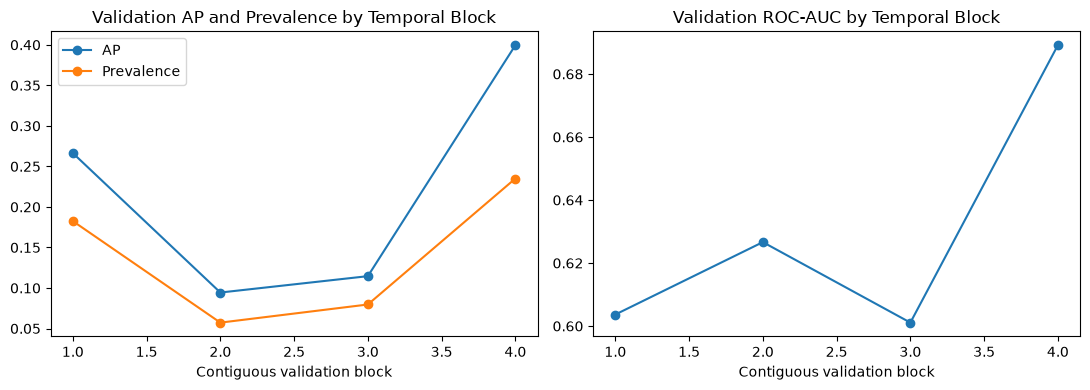

,feature,mean_ap_decrease,std_ap_decrease
0,emp.var.rate,0.104831,0.010614
1,pdays,0.031669,0.004551
2,previous,0.026429,0.002493
3,month,0.025199,0.006413
4,poutcome,0.019169,0.001816
5,contact,0.004580,0.001015
6,nr.employed,0.004270,0.003816
7,education,0.004252,0.001595
8,campaign,0.002294,0.000629
9,default,0.002268,0.000419


In [6]:
temporal_rows = []
for block, positions in enumerate(np.array_split(np.arange(len(y_valid)), 4), start=1):
    block_y = y_valid.iloc[positions]
    block_scores = selected_scores[positions]
    temporal_rows.append(
        {
            "block": block,
            "rows": len(positions),
            "positive_rate": block_y.mean(),
            "ap": average_precision_score(block_y, block_scores),
            "roc_auc": roc_auc_score(block_y, block_scores),
        }
    )
temporal_results = pd.DataFrame(temporal_rows)
display(temporal_results.round(6))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(temporal_results["block"], temporal_results["ap"], marker="o", label="AP")
axes[0].plot(
    temporal_results["block"],
    temporal_results["positive_rate"],
    marker="o",
    label="Prevalence",
)
axes[0].set_title("Validation AP and Prevalence by Temporal Block")
axes[0].set_xlabel("Contiguous validation block")
axes[0].legend()
axes[1].plot(temporal_results["block"], temporal_results["roc_auc"], marker="o")
axes[1].set_title("Validation ROC-AUC by Temporal Block")
axes[1].set_xlabel("Contiguous validation block")
plt.tight_layout()
plt.show()

importance = permutation_importance(
    selected_pipeline,
    X_valid,
    y_valid,
    scoring="average_precision",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
permutation_results = (
    pd.DataFrame(
        {
            "feature": modeling_features,
            "mean_ap_decrease": importance.importances_mean,
            "std_ap_decrease": importance.importances_std,
        }
    )
    .sort_values("mean_ap_decrease", ascending=False)
    .reset_index(drop=True)
)
display(permutation_results.head(10).round(6))

## 8. Model Selection and Handoff

Consolidate the experiments into a common registry with hypothesis, data scope, primary result, and decision fields. Then record the frozen development configuration. Stage 6 must reconstruct it without further feature, model, hyperparameter, or ranking-policy selection; fit on Train+Validation; and evaluate Test once.

In [7]:
EXPERIMENT_COLUMNS = [
    "experiment_id",
    "stage",
    "hypothesis",
    "data_scope",
    "candidate",
    "primary_metric",
    "primary_value",
    "decision",
]
registry_rows = [
    {
        "experiment_id": "baseline-reproduction",
        "stage": "baseline",
        "hypothesis": "Notebook 03 baseline is reproducible in the locked environment.",
        "data_scope": "Train fit; Validation evaluation",
        "candidate": baseline_result["candidate"],
        "primary_metric": "average_precision",
        "primary_value": baseline_result["ap"],
        "decision": "reproduced",
    },
    {
        "experiment_id": "pdays-representation",
        "stage": "feature_preprocessing",
        "hypothesis": "Separating the 999 sentinel improves ranking.",
        "data_scope": "Train fit; Validation evaluation",
        "candidate": engineered_result["candidate"],
        "primary_metric": "average_precision_gain",
        "primary_value": feature_ap_gain,
        "decision": f"use {selected_pdays_representation} pdays",
    },
]
for row in cv_comparison.itertuples(index=False):
    registry_rows.append(
        {
            "experiment_id": "model-family-comparison",
            "stage": "model_comparison",
            "hypothesis": "A nonlinear family may improve time-aware Train CV AP.",
            "data_scope": "Train-only TimeSeriesSplit (4 folds)",
            "candidate": row.model_family,
            "primary_metric": "mean_cv_average_precision",
            "primary_value": row.mean_cv_ap,
            "decision": "tune"
            if row.model_family in {"Logistic Regression", best_nonlinear_name}
            else "do not tune",
        }
    )
for row in validation_results.itertuples(index=False):
    registry_rows.append(
        {
            "experiment_id": "frozen-validation-comparison",
            "stage": "model_selection",
            "hypothesis": "Train-tuned candidates may improve Validation ranking.",
            "data_scope": "Validation evaluation after Train-only tuning",
            "candidate": row.candidate,
            "primary_metric": "average_precision",
            "primary_value": row.ap,
            "decision": "selected"
            if row.candidate == selected_candidate_name
            else "not selected",
        }
    )
experiment_registry = pd.DataFrame(registry_rows, columns=EXPERIMENT_COLUMNS)
display(experiment_registry.round({"primary_value": 6}))

final_configuration = {
    "candidate": selected_candidate_name,
    "pdays_representation": selected_pdays_representation,
    "model_class": type(selected_pipeline.named_steps["model"]).__name__,
    "model_params": selected_pipeline.named_steps["model"].get_params(),
    "modeling_features": modeling_features,
    "excluded_features": excluded_features,
    "random_state": RANDOM_STATE,
    "selection_reason": selection_reason,
    "validation_ap": float(selected_row["ap"]),
    "validation_roc_auc": float(selected_row["roc_auc"]),
    "validation_lift_at_10pct": float(selected_row["lift_at_10pct"]),
}
display(
    pd.Series(
        {
            key: final_configuration[key]
            for key in [
                "candidate",
                "pdays_representation",
                "model_class",
                "selection_reason",
                "validation_ap",
                "validation_roc_auc",
                "validation_lift_at_10pct",
            ]
        },
        name="value",
    ).to_frame()
)
display(pd.Series(final_configuration["model_params"], name="value").to_frame())
print("Test data was not materialized, inspected, or evaluated in this notebook.")

,experiment_id,stage,hypothesis,data_scope,candidate,primary_metric,primary_value,decision
0,baseline-reproduction,baseline,Notebook 03 baseline is reproducible in the lo...,Train fit; Validation evaluation,Baseline Logistic Regression,average_precision,0.297231,reproduced
1,pdays-representation,feature_preprocessing,Separating the 999 sentinel improves ranking.,Train fit; Validation evaluation,Logistic Regression — engineered pdays,average_precision_gain,-0.008997,use raw pdays
2,model-family-comparison,model_comparison,A nonlinear family may improve time-aware Trai...,Train-only TimeSeriesSplit (4 folds),Logistic Regression,mean_cv_average_precision,0.083139,tune
3,model-family-comparison,model_comparison,A nonlinear family may improve time-aware Trai...,Train-only TimeSeriesSplit (4 folds),HistGradientBoosting,mean_cv_average_precision,0.064833,tune
4,model-family-comparison,model_comparison,A nonlinear family may improve time-aware Trai...,Train-only TimeSeriesSplit (4 folds),Random Forest,mean_cv_average_precision,0.063195,do not tune
5,frozen-validation-comparison,model_selection,Train-tuned candidates may improve Validation ...,Validation evaluation after Train-only tuning,Baseline Logistic Regression,average_precision,0.297231,selected
6,frozen-validation-comparison,model_selection,Train-tuned candidates may improve Validation ...,Validation evaluation after Train-only tuning,Tuned Logistic Regression,average_precision,0.293450,not selected
7,frozen-validation-comparison,model_selection,Train-tuned candidates may improve Validation ...,Validation evaluation after Train-only tuning,Tuned HistGradientBoosting,average_precision,0.169968,not selected


,value
candidate,Baseline Logistic Regression
pdays_representation,raw
model_class,LogisticRegression
selection_reason,AP within 0.005 and materially higher Lift@10%
validation_ap,0.297231
validation_roc_auc,0.692923
validation_lift_at_10pct,2.783913


,value
C,1.0
class_weight,None
dual,False
fit_intercept,True
intercept_scaling,1
l1_ratio,0.0
max_iter,1000
n_jobs,None
penalty,deprecated
random_state,None


Test data was not materialized, inspected, or evaluated in this notebook.


## 9. Conclusions & Deliverables

### Results

- The baseline was reproduced: Validation AP `0.297231`, ROC-AUC `0.692923`, and Lift@10% `2.783913`.
- Splitting the `pdays = 999` sentinel from elapsed days reduced AP by `0.008997`; retain raw `pdays`.
- Logistic Regression had the highest Train-only four-fold mean CV AP (`0.083139`), ahead of HistGradientBoosting (`0.064833`) and Random Forest (`0.063195`).
- Tuning did not improve Validation AP: tuned Logistic Regression reached `0.293450`, while tuned HistGradientBoosting reached `0.169968`.
- Validation temporal-block AP ranged from `0.094411` to `0.399525`, indicating substantial time/prevalence sensitivity.

### Interpretation and Decision

Freeze the baseline configuration: raw `pdays`, scaled numeric inputs, one-hot encoded categorical inputs, and `LogisticRegression(max_iter=1000)` with otherwise default parameters. It retained the highest Validation AP and materially higher Lift@10% than the tuned Logistic Regression within the `0.005` AP tie margin. Added nonlinear complexity was not justified. Section 8 is the frozen handoff to Notebook 05.

### Limitations

- A single chronological Validation period cannot establish stability across every future campaign.
- Validation selected the `pdays` representation and final candidate; repeated experimentation can create selection bias.
- Temporal blocks are diagnostics, not independent deployment periods.
- Permutation importance is associational and does not estimate causal effects.
- Top-K evaluation is record-based and does not simulate daily capacity or unique-customer constraints.
- Probability calibration has not been used for selection.

### Handoff to Final Evaluation

Notebook 05 must use the frozen Section 8 configuration, refit all learned steps on Train+Validation, and evaluate Test once. An unexpectedly weak Test result must be reported rather than used to reopen model selection.